# 14 光流：两帧图像 → 每个像素的运动向量

观察 `(u,v)` 位移矩阵、箭头图和彩色光流图；用已知平移量计算端点误差 EPE。
运行 OpenCV Farnebäck 稠密光流，不需要显卡或模型权重。


In [1]:
from pathlib import Path
import sys, os
for folder in [Path.cwd(), *Path.cwd().parents]:
    if (folder / "course_utils.py").exists():
        sys.path.insert(0, str(folder))
        break
else:
    raise FileNotFoundError("请从完整项目的根目录或 notebooks 目录运行。")
from course_utils import setup, device, save_figure
ROOT = setup(seed=42)
import numpy as np
import cv2
import matplotlib.pyplot as plt
from IPython import get_ipython
if get_ipython() is not None:
    get_ipython().run_line_magic("matplotlib", "inline")
import torch
from torch import nn
import torch.nn.functional as F
dev = device()
torch.set_num_threads(2)
print("计算设备:", dev)


计算设备: cpu


## 1. 可验证的输入

对同一纹理图像施加已知平移 dx=4、dy=2 px。二维图像坐标 x 向右、y 向下，因此正 v 表示向下移动。


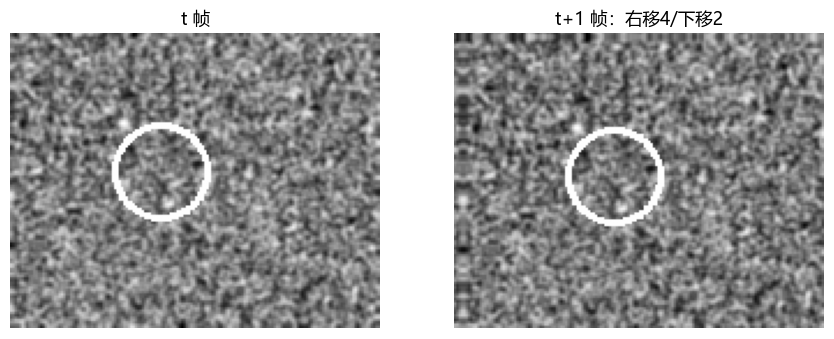

输入局部像素矩阵:
 [[106 110 114 128 125]
 [101  94 100 129 143]
 [122 106  95 110 132]
 [129 116 102  97 109]]


In [2]:
rng = np.random.default_rng(8)
frame0 = cv2.GaussianBlur(rng.integers(0,256,(128,160),dtype=np.uint8),(5,5),.9)
cv2.circle(frame0,(65,60),20,220,2)
dx, dy = 4., 2.
M = np.float32([[1,0,dx],[0,1,dy]])
frame1 = cv2.warpAffine(frame0,M,(160,128),borderMode=cv2.BORDER_REFLECT)
fig,axs=plt.subplots(1,2,figsize=(10,4))
for ax,im,title in zip(axs,[frame0,frame1],["t 帧", "t+1 帧：右移4/下移2"]):
    ax.imshow(im,cmap="gray");ax.set_title(title);ax.axis("off")
save_figure("14_flow_inputs")
print("输入局部像素矩阵:\n",frame0[60:64,60:65])


## 2. 稠密光流

`flow[y,x,0]=u`、`flow[y,x,1]=v`，单位为相邻两帧间的像素位移。
只有已知帧间隔，才能转换成像素/秒；要变成米/秒还需要几何标定。

矩阵怎么读：输入两帧均为 `[128,160]` 灰度矩阵，输出是 `[128,160,2]`。若 `flow[60,60]=[4,2]`，表示当前帧 `(x=60,y=60)` 附近内容在下一帧移动到约 `(64,62)`；这两个值不是颜色，也不是下一帧的绝对坐标。`u`、`v` 的局部矩阵分别展示水平和垂直分量。


输出 [H,W,2]: (128, 160, 2)
u 局部矩阵:
 [[4. 4. 4. 4. 4.]
 [4. 4. 4. 4. 4.]
 [4. 4. 4. 4. 4.]
 [4. 4. 4. 4. 4.]]
v 局部矩阵:
 [[2. 2. 2. 2. 2.]
 [2. 2. 2. 2. 2.]
 [2. 2. 2. 2. 2.]
 [2. 2. 2. 2. 2.]]


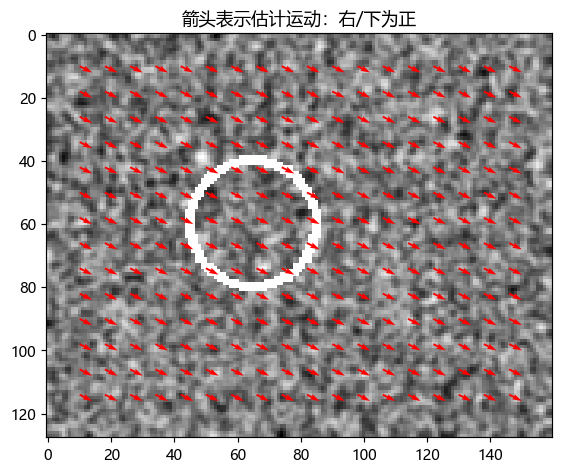

WindowsPath('D:/workspace/cv/cv-beginner-course/outputs/14_flow_vectors.png')

In [3]:
flow = cv2.calcOpticalFlowFarneback(frame0,frame1,None,.5,3,21,5,7,1.5,0)
print("输出 [H,W,2]:",flow.shape)
print("u 局部矩阵:\n",np.round(flow[60:64,60:65,0],2))
print("v 局部矩阵:\n",np.round(flow[60:64,60:65,1],2))
y,x=np.mgrid[10:118:8,10:150:8]
plt.figure(figsize=(8,5));plt.imshow(frame0,cmap="gray")
plt.quiver(x,y,flow[y,x,0],flow[y,x,1],color="red",angles="xy",scale_units="xy",scale=1)
plt.title("箭头表示估计运动：右/下为正")
save_figure("14_flow_vectors")


## 3. 用真实位移计算 EPE

$EPE=\sqrt{(u-u^*)^2+(v-v^*)^2}$。评价只使用远离图像边界的区域，避免边界填充影响。
还检查“用流场把下一帧采样回当前帧”后的亮度差。


中央区域平均 EPE=0.0007 px
配准后中央亮度 MAE: 0.0


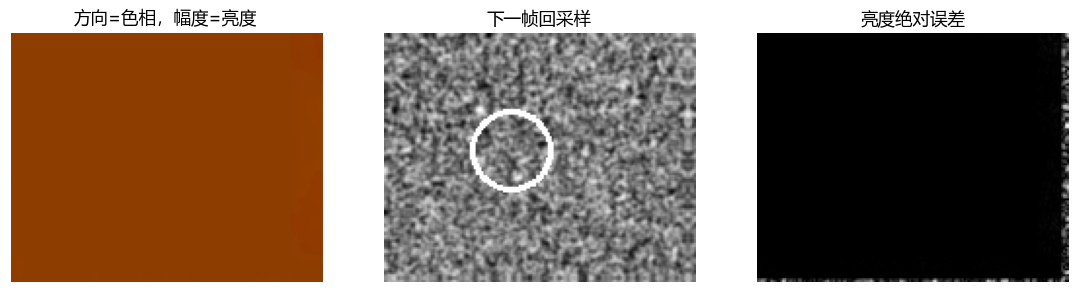

In [4]:
margin=20
interior=flow[margin:-margin,margin:-margin]
epe=np.sqrt((interior[...,0]-dx)**2+(interior[...,1]-dy)**2)
print(f"中央区域平均 EPE={epe.mean():.4f} px")
yy,xx=np.mgrid[0:128,0:160].astype(np.float32)
warped=cv2.remap(frame1,xx+flow[...,0],yy+flow[...,1],cv2.INTER_LINEAR,borderMode=cv2.BORDER_REFLECT)
photometric=np.abs(warped.astype(float)-frame0.astype(float))
print("配准后中央亮度 MAE:",photometric[margin:-margin,margin:-margin].mean())
mag,ang=cv2.cartToPolar(flow[...,0],flow[...,1])
hsv=np.zeros((128,160,3),np.uint8)
hsv[...,0]=np.mod(ang*90/np.pi,180).astype(np.uint8)
hsv[...,1]=255;hsv[...,2]=np.clip(mag/8*255,0,255).astype(np.uint8)
flow_rgb=cv2.cvtColor(hsv,cv2.COLOR_HSV2RGB)
fig,axs=plt.subplots(1,3,figsize=(13,4))
for ax,im,title in zip(axs,[flow_rgb,warped,photometric],["方向=色相，幅度=亮度", "下一帧回采样", "亮度绝对误差"]):
    ax.imshow(im,cmap=None if im.ndim==3 else "gray");ax.set_title(title);ax.axis("off")
save_figure("14_flow_outputs")
assert np.isfinite(flow).all() and flow.shape[-1]==2


## 4. 真实图片的可控运动

将项目内的水果照片平移后估计光流；注意低纹理区域与边界的误差变化。这仍是已知人工运动的照片实验，不是实拍视频评测。


真实照片人工平移 EPE=0.045 px


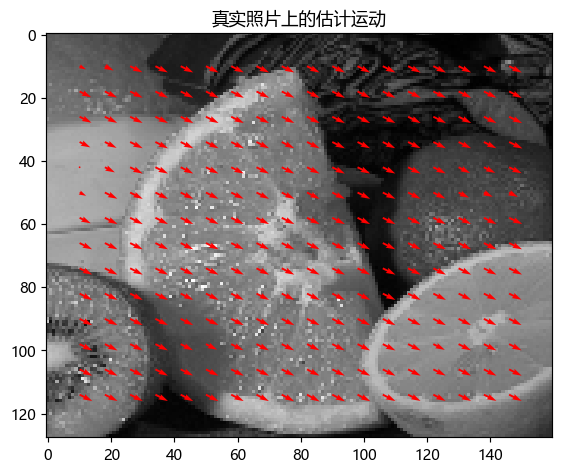

In [5]:
photo_path=ROOT/"assets/photos/fruits.jpg"
if photo_path.exists():
    a=cv2.resize(cv2.imread(str(photo_path),cv2.IMREAD_GRAYSCALE),(160,128))
    b=cv2.warpAffine(a,M,(160,128),borderMode=cv2.BORDER_REFLECT)
    f=cv2.calcOpticalFlowFarneback(a,b,None,.5,3,21,5,7,1.5,0)
    err=np.linalg.norm(f[20:-20,20:-20]-np.array([dx,dy]),axis=-1)
    print(f"真实照片人工平移 EPE={err.mean():.3f} px")
    plt.figure(figsize=(8,5));plt.imshow(a,cmap="gray")
    plt.quiver(x,y,f[y,x,0],f[y,x,1],color="red",angles="xy",scale_units="xy",scale=1)
    plt.title("真实照片上的估计运动")
    save_figure("14_flow_photo")
else:
    print("请先准备项目真实照片素材。")


## 5. 练习与边界

把位移改为 20 px、改变金字塔层数；再只改变亮度，观察亮度一致性假设的影响。
真实场景还会遇到遮挡、新出现区域、快速运动和运动模糊。可比较稀疏 Lucas–Kanade 与本课稠密 Farnebäck 的输出范围。

来源：[OpenCV 光流教程](https://docs.opencv.org/4.x/d4/dee/tutorial_optical_flow.html)。
